# Chapitre 3 - Cours 3 : B-trees, et la comparaison avec les arbres LSM

Ce notebook couvre la section *B-Trees* (avec *Making B-trees reliable* et *B-tree
optimizations*) puis la section *Comparing B-Trees and LSM-Trees* (*Advantages of
LSM-trees*, *Downsides of LSM-trees*). Nous implémentons un arbre B+ à pages
(`S.BPlusTree`), provoquons une panne au milieu d'un éclatement de page, puis comparons
mesures à l'appui le B-tree et le moteur LSM du cours 2.

**Plan.**

1. La structure d'un B-tree : pages, références, facteur de branchement.
2. Insertion et éclatement de pages ; hauteur logarithmique ; taux de remplissage.
3. Rendre un B-tree fiable : la panne au milieu d'un éclatement, et le WAL.
4. Quelques variantes : copie sur écriture, clés abrégées, feuilles chaînées.
5. Comparer B-trees et arbres LSM : lectures, écritures séquentielles ou aléatoires,
   amplification d'écriture, pics de latence, espace disque.

In [1]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)


def dessiner_btree(pages, root, ax, chemin=(), nouvelles=(), titre=None, couleur=INDIGO):
    """Dessine un arbre B+ : une boîte par page, les clés dedans, les liens vers les filles.
    `chemin` : pages surlignées (parcours d'une recherche) ; `nouvelles` : pages créées."""
    niveaux, front = [], [root]
    while front:
        niveaux.append(front)
        front = [c for pid in front if not pages[pid].leaf for c in pages[pid].children]
    pos, largeur = {}, {}
    feuilles = niveaux[-1]
    x = 0.0
    for pid in feuilles:
        w = 0.55 * max(1, len(pages[pid].keys)) + 0.3
        pos[pid], largeur[pid] = (x + w / 2, 0), w
        x += w + 0.35
    for depth in range(len(niveaux) - 2, -1, -1):
        y = len(niveaux) - 1 - depth
        for pid in niveaux[depth]:
            kids = pages[pid].children
            cx = (pos[kids[0]][0] + pos[kids[-1]][0]) / 2
            w = 0.55 * max(1, len(pages[pid].keys)) + 0.3
            pos[pid], largeur[pid] = (cx, y), w
    for pid, (cx, y) in pos.items():
        p = pages[pid]
        if not p.leaf:
            n = len(p.children)
            for j, c in enumerate(p.children):
                sx = cx - largeur[pid] / 2 + largeur[pid] * (j + 0.5) / n
                tx, ty = pos[c]
                on = pid in chemin and c in chemin
                ax.plot([sx, tx], [y - 0.22, ty + 0.22], color=AMBER if on else "#CBD5E1",
                        lw=2.2 if on else 1, zorder=1)
    for pid, (cx, y) in pos.items():
        p = pages[pid]
        surl = pid in chemin
        neuf = pid in nouvelles
        fc = LIGHT[AMBER] if surl else (LIGHT[TEAL] if neuf else LIGHT[couleur])
        ec = AMBER if surl else (TEAL if neuf else couleur)
        ax.add_patch(plt.Rectangle((cx - largeur[pid] / 2, y - 0.22), largeur[pid], 0.44, facecolor=fc,
                                   edgecolor=ec, lw=1.8 if surl or neuf else 1.2, zorder=2))
        ax.text(cx, y, "  ".join(str(k) for k in p.keys), ha="center", va="center", fontsize=8.5,
                color=SLATE, zorder=3, fontweight="bold" if not p.leaf else "normal")
        ax.text(cx - largeur[pid] / 2, y + 0.3, f"p{pid}", fontsize=7, color=GRAY, zorder=3)
    for a, b in zip(feuilles, feuilles[1:]):
        ax.annotate("", xy=(pos[b][0] - largeur[b] / 2, -0.32), xytext=(pos[a][0] + largeur[a] / 2, -0.32),
                    arrowprops=dict(arrowstyle="-|>", color=GRAY, lw=0.8))
    ax.set_xlim(-0.3, x)
    ax.set_ylim(-0.6, len(niveaux) - 0.4)
    ax.axis("off")
    if titre:
        ax.set_title(titre)
    return pos

## 1. La structure d'un B-tree (section *B-Trees*)

**Une autre philosophie.** Les moteurs à journal découpent la base en segments de
taille variable, écrits une fois puis immuables. Le **B-tree** (1970, qualifié
d'« ubiquitaire » moins de dix ans plus tard) découpe au contraire la base en **pages
de taille fixe** (traditionnellement 4 Kio ; 8 Kio pour PostgreSQL, 16 Kio pour MySQL)
et **réécrit une page en place**. C'est la structure d'index standard de presque toutes
les bases relationnelles.

Chaque page a un **numéro** ; une page peut en désigner une autre par ce numéro, comme
un pointeur mais sur disque (l'offset dans le fichier vaut numéro × taille de page). On
construit ainsi un arbre :

- la **racine** est le point de départ de toute recherche ;
- une page **interne** contient des clés et des références vers des pages filles ;
  chaque fille est responsable d'un **intervalle continu** de clés, et les clés de la
  page mère en marquent les frontières ;
- les **feuilles** contiennent les clés individuelles, avec la valeur ou une référence
  vers elle.

Le nombre de références vers des filles dans une page est le **facteur de branchement**
(plusieurs centaines en pratique). Pour notre dessin, des pages de 4 clés au plus.

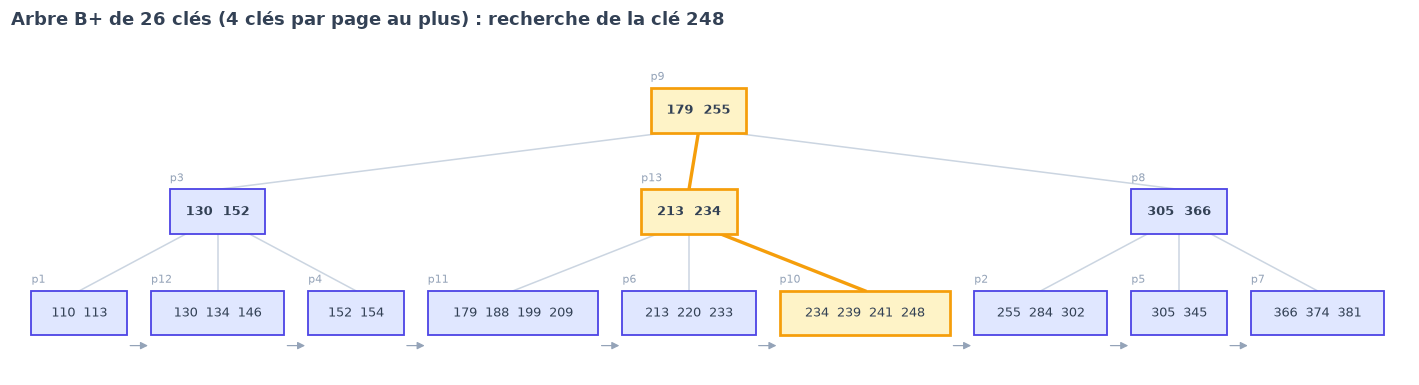

pages lues : p9 [179, 255] -> p13 [213, 234] -> p10 [234, 239, 241, 248]


In [2]:
arbre = S.BPlusTree(max_keys=4)
for k in random.Random(4).sample(range(100, 400), 26):
    arbre.insert(k, f"val{k}")
cible = sorted(k for k, _ in arbre.items())[17]
chemin = [pid for pid, _ in arbre.lookup_path(cible)]
fig, ax = plt.subplots(figsize=(13, 3.6))
dessiner_btree(arbre.pages, arbre.root, ax, chemin=chemin,
               titre=f"Arbre B+ de {len(arbre)} clés (4 clés par page au plus) : recherche de la clé {cible}")
plt.tight_layout(); plt.show()
print("pages lues :", " -> ".join(f"p{pid} {keys}" for pid, keys in arbre.lookup_path(cible)))

La recherche part de la racine, choisit à chaque niveau la référence dont l'intervalle
contient la clé (une recherche dichotomique dans la page) et descend jusqu'à la
feuille : **une page lue par niveau**. Les flèches grises sous les feuilles sont des
références vers la feuille voisine, utiles pour les parcours d'intervalle (section 4).

> **À retenir.** Un B-tree est un arbre de pages de taille fixe, triées par clé ; chaque
> page interne découpe son intervalle de clés entre ses filles. Une recherche lit une
> page par niveau.

## 2. Insertion, éclatement de pages et hauteur (section *B-Trees*)

**Mettre à jour** une clé existante : on trouve sa feuille et on réécrit cette page.
**Insérer** une clé : on trouve la feuille dont l'intervalle la contient et on l'y
ajoute. S'il n'y a plus de place, la page est **éclatée** en deux pages à moitié
pleines, et la page mère reçoit une nouvelle frontière et une nouvelle référence. Si la
mère déborde à son tour, l'éclatement remonte, jusqu'à la racine éventuellement : on
crée alors une nouvelle racine au-dessus. L'arbre reste ainsi **équilibré** : toutes les
feuilles sont à la même profondeur, $O(\log n)$.

Insérons une clé dans une feuille pleine et regardons ce qui change.

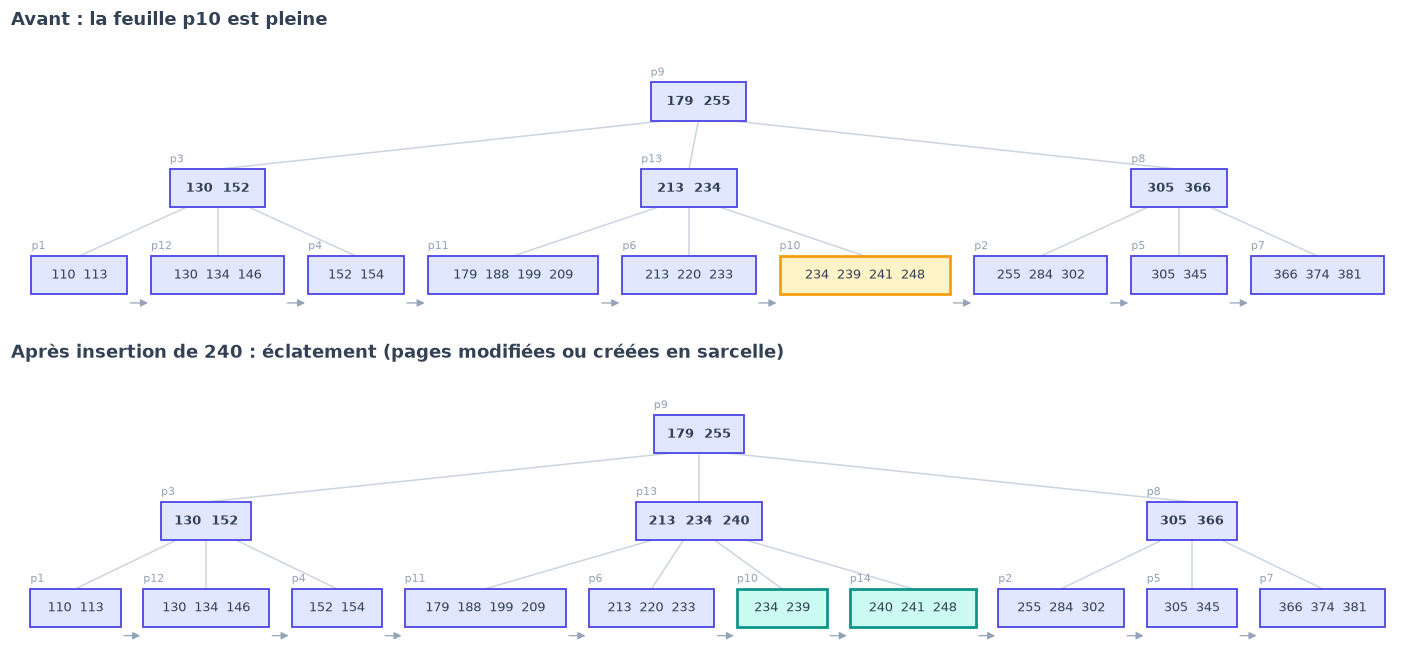

In [3]:
pleine = next(pid for pid, p in arbre.pages.items() if p.leaf and len(p.keys) == 4)
k_new = arbre.pages[pleine].keys[1] + 1
avant_pages = set(arbre.pages)
avant = {pid: S.Page(p.id, p.leaf, list(p.keys), list(p.children)) for pid, p in arbre.pages.items()}
avant_root = arbre.root
arbre.insert(k_new, "nouveau")
nouvelles = set(arbre.pages) - avant_pages
fig, axes = plt.subplots(2, 1, figsize=(13, 6.2))
dessiner_btree(avant, avant_root, axes[0], chemin=[pleine], titre=f"Avant : la feuille p{pleine} est pleine")
dessiner_btree(arbre.pages, arbre.root, axes[1], nouvelles=nouvelles | {pleine},
               titre=f"Après insertion de {k_new} : éclatement (pages modifiées ou créées en sarcelle)")
plt.tight_layout(); plt.show()

Un seul `insert` a modifié plusieurs pages : la feuille d'origine (qui garde la moitié
basse), la nouvelle feuille (moitié haute) et la page mère (nouvelle frontière). Si la
mère était pleine, l'éclatement a remonté d'un niveau. **Plusieurs pages réécrites pour
une seule opération** : retenons-le pour la section 3.

**Hauteur et facteur de branchement.** Avec un facteur $b$, un arbre de hauteur $h$
indexe jusqu'à $b^{h}$ clés : $h \approx \log_b n$. Le livre donne un ordre de
grandeur : quatre niveaux de pages de 4 Kio avec un branchement de 500 permettent de
stocker jusqu'à 250 To. Vérifions : $500^4 \times 4\,096 \approx 2{,}56 \times 10^{14}$
octets, soit environ 256 To. Mesurons la hauteur de vrais arbres.

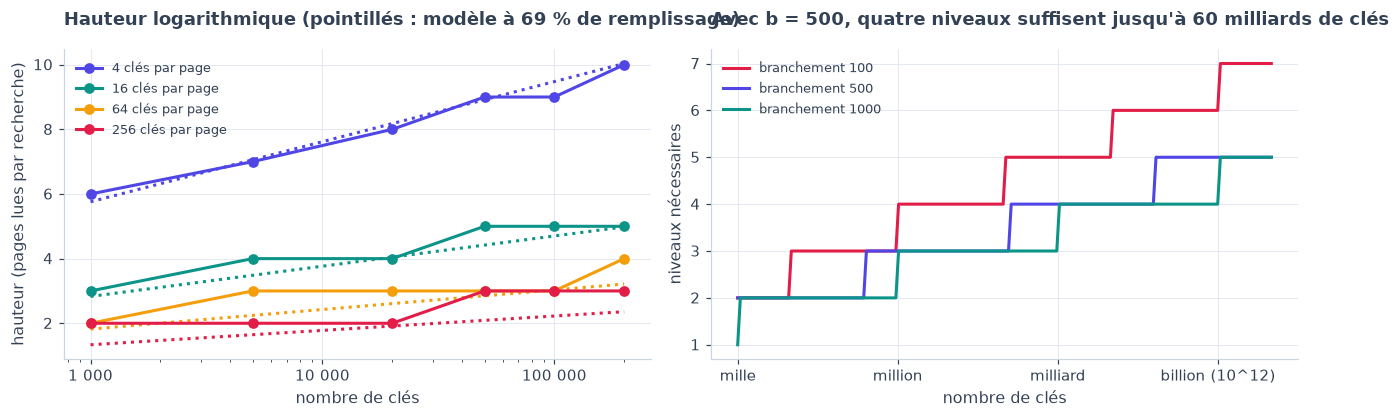

In [4]:
rows = []
for b in [4, 16, 64, 256]:
    t = S.BPlusTree(max_keys=b)
    cles = list(range(200_000))
    random.Random(0).shuffle(cles)
    jalons = {1_000, 5_000, 20_000, 50_000, 100_000, 200_000}
    for n, k in enumerate(cles, 1):
        t.insert(k, None)
        if n in jalons:
            theorie = 1 + np.log(n / (0.69 * b)) / np.log(0.69 * (b + 1))
            rows.append(dict(branchement=b, cles=n, hauteur=t.height, theorie=theorie))
haut = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]
for (b, g), c in zip(haut.groupby("branchement"), COLORS):
    ax.plot(g.cles, g.hauteur, "o-", color=c, label=f"{b} clés par page")
    ax.plot(g.cles, g.theorie, ":", color=c)
ax.set_xscale("log"); S.plain_log_ticks(ax, "x")
ax.set_xlabel("nombre de clés"); ax.set_ylabel("hauteur (pages lues par recherche)")
ax.set_title("Hauteur logarithmique (pointillés : modèle à 69 % de remplissage)")
ax.legend(fontsize=8.5)
ax = axes[1]
n_cles = np.logspace(3, 13, 200)
for b, c in [(100, ROSE), (500, INDIGO), (1000, TEAL)]:
    ax.plot(n_cles, np.ceil(np.log(n_cles) / np.log(b)), color=c, label=f"branchement {b}")
ax.set_xscale("log")
ax.set_xticks([1e3, 1e6, 1e9, 1e12], ["mille", "million", "milliard", "billion (10^12)"])
ax.minorticks_off()
ax.set_xlabel("nombre de clés"); ax.set_ylabel("niveaux nécessaires")
ax.set_title("Avec b = 500, quatre niveaux suffisent jusqu'à 60 milliards de clés")
ax.legend(fontsize=8.5)
finish(fig)
plt.show()

La hauteur croît par paliers, comme $\log_b n$ : avec 256 clés par page, 200 000 clés
tiennent en trois niveaux. Le modèle en pointillés,
$h \approx 1 + \log_{0{,}69(b+1)}\big(n / 0{,}69\,b\big)$, suppose des pages remplies à
69 % : c'est le **taux de remplissage** moyen des pages quand les clés arrivent
dans un ordre aléatoire (un résultat classique : $\ln 2 \approx 0{,}69$). Si les clés
arrivent **dans l'ordre** (identifiants croissants, horodatages), l'éclatement au milieu
laisse derrière lui des pages à moitié vides. Vérifions.

In [5]:
rows = []
for ordre in ["aléatoire", "croissant"]:
    t = S.BPlusTree(max_keys=64)
    cles = list(range(100_000))
    if ordre == "aléatoire":
        random.Random(1).shuffle(cles)
    for k in cles:
        t.insert(k, None)
    rows.append(dict(ordre=ordre, remplissage=t.fill_factor(), feuilles=t.level_counts()[-1], hauteur=t.height))
rempl = pd.DataFrame(rows)
rempl

,ordre,remplissage,feuilles,hauteur
0,aléatoire,0.701,2230,3
1,croissant,0.500,3124,4


Ordre aléatoire : environ 69 % de remplissage. Ordre croissant : 50 %, presque deux fois
plus de feuilles. C'est pourquoi les vrais moteurs détectent les insertions en fin
d'index et éclatent alors la page **à droite** (la page de gauche reste pleine), comme
le fait par exemple SQLite ou InnoDB.

> **À retenir.** L'éclatement de pages garde l'arbre équilibré : hauteur $\approx
> \log_b n$, trois ou quatre niveaux pour la plupart des bases. Une insertion peut
> réécrire plusieurs pages, et le taux de remplissage dépend de l'ordre des clés.

## 3. Rendre un B-tree fiable (section *Making B-trees reliable*)

**Le danger.** L'écriture élémentaire d'un B-tree est l'**écrasement d'une page en
place**, en supposant que la page ne change pas d'emplacement (toutes les références
vers elle restent valides). Mais un éclatement réécrit **plusieurs pages** : si la base
tombe en panne après en avoir écrit seulement une partie, l'arbre est **corrompu**. Pire,
si le matériel ne sait pas écrire une page de façon atomique, une page peut être écrite
à moitié (*torn page*).

**Expérience.** Notre arbre garde une copie de « ce qui est sur le disque » et écrit les
pages d'un éclatement dans un ordre naturel : nouvelle feuille, ancienne feuille, mère,
puis page méta si la racine change (elle désigne la racine). On provoque une panne
après 0 à 4 écritures.

In [6]:
def arbre_de_demo(wal=False):
    t = S.BPlusTree(max_keys=4, track_disk=True, wal=wal)
    for k in [10, 20, 30, 40, 50, 60, 70, 80]:  # la dernière feuille [50 60 70 80] est pleine
        t.insert(k, k)
    return t


lignes = []
for j in range(0, 5):
    t = arbre_de_demo()
    try:
        t.insert(55, 55, crash_after=j)
        etat = "pas de panne"
    except S.SimulatedCrash as e:
        etat = str(e)
    r = S.BPlusTree.check(t.disk, t.disk_root())
    lignes.append(dict(pages_ecrites=j, evenement=etat, cles_atteignables=r["cles_atteignables"],
                       cles_perdues=r["cles_perdues"], pages_orphelines=r["pages_orphelines"]))
pd.DataFrame(lignes)

,pages_ecrites,evenement,cles_atteignables,cles_perdues,pages_orphelines
0,0,panne après 0 écriture(s) de page sur 3,8,[],[]
1,1,panne après 1 écriture(s) de page sur 3,8,[],[5]
2,2,panne après 2 écriture(s) de page sur 3,6,"[60, 70, 80]",[5]
3,3,pas de panne,9,[],[]
4,4,pas de panne,9,[],[]


Avant l'insertion, l'arbre contient 8 clés et la feuille qui doit recevoir 55 est
pleine. Selon le moment de la panne :

- 0 écriture : l'insertion est perdue mais l'arbre est intact (cohérent) ;
- 1 écriture : la nouvelle feuille est sur le disque mais personne ne la référence :
  une **page orpheline** (espace perdu, pas de clé perdue) ;
- 2 écritures : l'ancienne feuille a été tronquée de sa moitié haute, mais la mère ne
  connaît pas encore la nouvelle feuille : des **clés existantes disparaissent**, alors
  qu'elles avaient été confirmées bien avant la panne. C'est la corruption que redoute le
  livre.

Dessinons l'état du disque dans ce dernier cas.

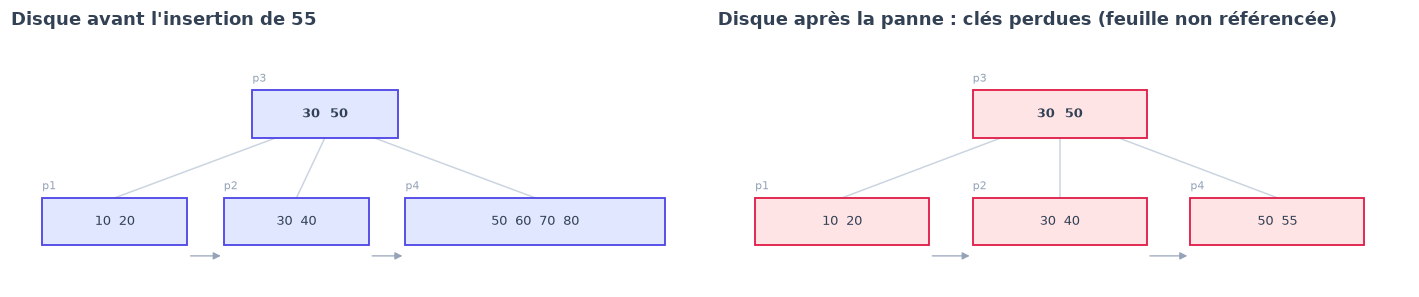

In [7]:
t = arbre_de_demo()
try:
    t.insert(55, 55, crash_after=2)
except S.SimulatedCrash:
    pass
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
avant = arbre_de_demo()
dessiner_btree(avant.disk, avant.disk_root(), axes[0], titre="Disque avant l'insertion de 55")
racine = t.disk_root()
atteignables = {pid for pid in t.disk if pid} - set(S.BPlusTree.check(t.disk, racine)["pages_orphelines"])
dessiner_btree({pid: p for pid, p in t.disk.items() if pid in atteignables}, racine, axes[1],
               titre="Disque après la panne : clés perdues (feuille non référencée)", couleur=ROSE)
plt.tight_layout(); plt.show()

**La parade : le journal d'écriture anticipée** (*write-ahead log*, WAL). Avant de
toucher aux pages de l'arbre, on écrit la modification dans un fichier append-only, et
on force son écriture sur le disque (`fsync`). Au redémarrage, on rejoue le journal pour
remettre l'arbre dans un état cohérent. (Dans les systèmes de fichiers, le même
mécanisme s'appelle la **journalisation**.) Le WAL permet aussi de **différer**
l'écriture des pages : on les garde modifiées en mémoire un moment, la durabilité étant
assurée par le journal. Notre implémentation journalise les images complètes des pages
modifiées.

In [8]:
lignes = []
for j in range(0, 5):
    t = arbre_de_demo(wal=True)
    try:
        t.insert(55, 55, crash_after=j)
    except S.SimulatedCrash:
        pass
    pages = t.recover_from_wal()
    r = S.BPlusTree.check(pages, pages[0].keys[0])
    lignes.append(dict(pages_ecrites_avant_panne=j, cles_apres_reprise=r["cles_atteignables"],
                       cles_perdues=r["cles_perdues"], pages_orphelines=r["pages_orphelines"]))
pd.DataFrame(lignes)

,pages_ecrites_avant_panne,cles_apres_reprise,cles_perdues,pages_orphelines
0,0,9,[],[]
1,1,9,[],[]
2,2,9,[],[]
3,3,9,[],[]
4,4,9,[],[]


Avec le WAL, quel que soit l'instant de la panne pendant l'écriture des pages, la
reprise retrouve les 9 clés : le journal contenait déjà toute l'opération. Le diagramme
espace-temps montre l'ordre qui rend cela possible : **journal d'abord, `fsync`,
confirmation au client, puis pages plus tard**.

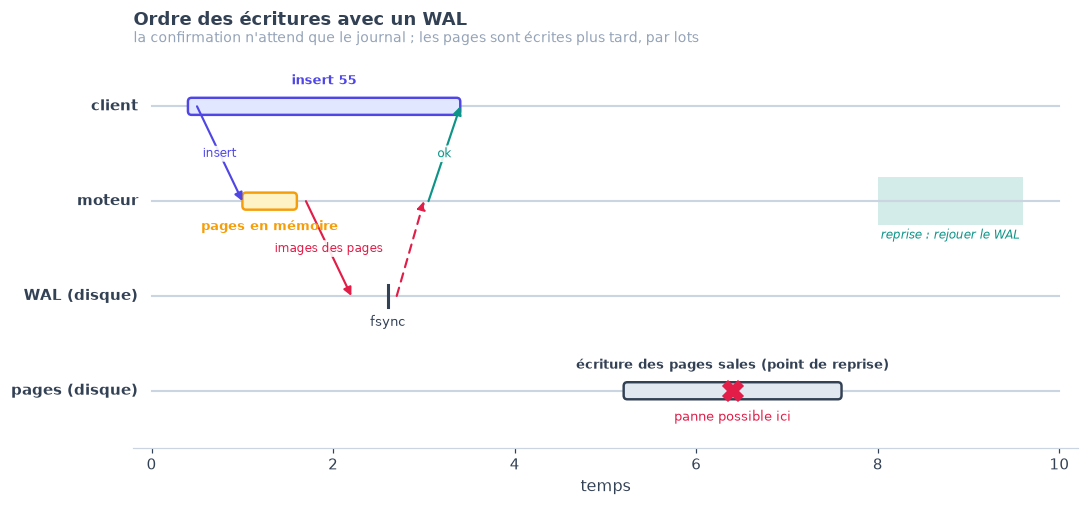

In [9]:
st = SpaceTime(["client", "moteur", "WAL (disque)", "pages (disque)"], t_max=10,
               title="Ordre des écritures avec un WAL",
               subtitle="la confirmation n'attend que le journal ; les pages sont écrites plus tard, par lots")
st.op("client", 0.4, 3.4, "insert 55", color=INDIGO)
st.msg("client", 0.5, "moteur", 1.0, "insert", color=INDIGO)
st.op("moteur", 1.0, 1.6, "pages en mémoire", color=AMBER, above=False)
st.msg("moteur", 1.7, "WAL (disque)", 2.2, "images des pages", color=ROSE)
st.event("WAL (disque)", 2.6, "fsync", kind="tick")
st.msg("WAL (disque)", 2.7, "moteur", 3.0, "", color=ROSE, style="dashed")
st.msg("moteur", 3.05, "client", 3.4, "ok", color=TEAL)
st.op("pages (disque)", 5.2, 7.6, "écriture des pages sales (point de reprise)", color=SLATE)
st.event("pages (disque)", 6.4, "panne possible ici", kind="crash")
st.span("moteur", 8.0, 9.6, "reprise : rejouer le WAL", color=TEAL, alpha=0.18)
st.show()

> **À retenir.** Un éclatement réécrit plusieurs pages en place ; une panne au milieu
> peut perdre des clés anciennes. Le WAL (journal d'abord, `fsync`, puis les pages)
> rend l'arbre réparable et permet de garder les pages modifiées en mémoire. La
> concurrence entre fils demande en plus des verrous légers sur les pages (*latches*).

## 4. Quelques variantes (section *B-tree optimizations*)

Après cinquante ans, les variantes abondent. Le livre en cite quatre :

- **copie sur écriture** (LMDB) : au lieu d'écraser une page et de tenir un WAL, on
  écrit la page modifiée **ailleurs**, puis de nouvelles versions des pages mères
  jusqu'à la racine. L'ancienne racine reste un instantané cohérent (utile pour la
  concurrence, chapitre 7) ;
- **clés abrégées** : dans les pages internes, une clé ne sert que de frontière ; il
  suffit d'en garder assez pour séparer deux intervalles. Plus de clés par page = un
  branchement plus grand = moins de niveaux ;
- **feuilles contiguës** sur le disque pour accélérer les parcours ordonnés (difficile à
  maintenir quand l'arbre grossit) ;
- **pointeurs supplémentaires**, par exemple vers les feuilles voisines, pour parcourir
  les clés dans l'ordre sans remonter vers les pages mères.

Chiffrons les deux dernières idées mesurables. D'abord, l'effet de la taille des clés
sur le branchement et la hauteur, pour un milliard de clés et des pages de 4 Kio
(références de 8 octets).

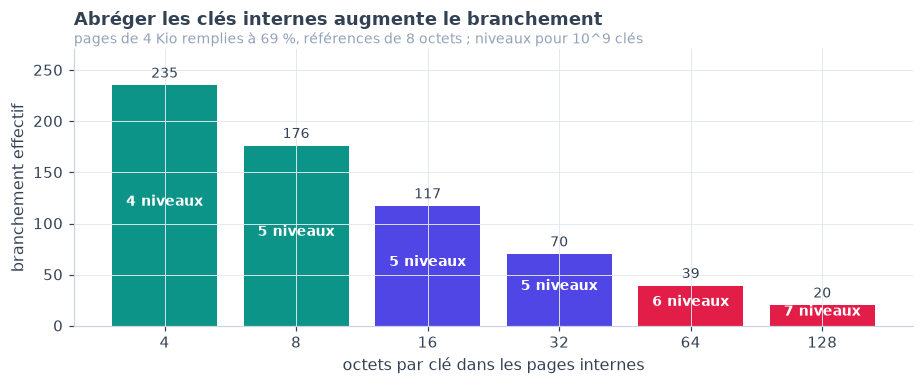

In [10]:
rows = []
for kb in [4, 8, 16, 32, 64, 128]:
    cap = S.btree_capacity(4096, key_bytes=kb, ref_bytes=8, fill=0.69)
    rows.append(dict(octets_par_cle=kb, branchement_effectif=cap["branchement"],
                     niveaux_pour_1e9_cles=int(np.ceil(np.log(1e9) / np.log(cap["branchement"]))) + 0))
cles_abregees = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
bars = ax.bar(cles_abregees.octets_par_cle.astype(str), cles_abregees.branchement_effectif,
              color=[TEAL, TEAL, INDIGO, INDIGO, ROSE, ROSE])
annotate_bars(ax, "{:.0f}")
for b_, n_ in zip(bars, cles_abregees.niveaux_pour_1e9_cles):
    ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height() / 2, f"{n_} niveaux", ha="center", color="white",
            fontsize=9, fontweight="bold")
ax.set_ylim(top=cles_abregees.branchement_effectif.max() * 1.15)
ax.set_xlabel("octets par clé dans les pages internes"); ax.set_ylabel("branchement effectif")
ax.set_title("Abréger les clés internes augmente le branchement")
subtitle(ax, "pages de 4 Kio remplies à 69 %, références de 8 octets ; niveaux pour 10^9 clés")
plt.tight_layout(); plt.show()

Passer de clés de 64 octets à 8 octets multiplie le branchement par plus de quatre et
économise un niveau, c'est-à-dire une lecture de page par recherche (souvent une E/S disque pour
les niveaux bas).

Ensuite, les **feuilles chaînées** : pour lire 2 000 clés consécutives, on descend une
fois puis on suit les références entre feuilles, au lieu de redescendre depuis la
racine pour chaque feuille.

In [11]:
t = S.BPlusTree(max_keys=64)
for k in random.Random(5).sample(range(1_000_000), 200_000):
    t.insert(k, None)
lo, hi = 300_000, 310_000
t.page_reads = 0
res = t.range(lo, hi)
chaine = t.page_reads
feuilles_touchees = chaine - t.height + 1
sans_chaine = feuilles_touchees * t.height
pd.DataFrame({"pages lues": [chaine, sans_chaine]},
             index=["avec pointeurs entre feuilles", "en redescendant depuis la racine pour chaque feuille"]).assign(
    cles_renvoyees=len(res))

,pages lues,cles_renvoyees
avec pointeurs entre feuilles,50,2010
en redescendant depuis la racine pour chaque feuille,188,2010


> **À retenir.** Les variantes de B-tree jouent sur la fiabilité (copie sur écriture au
> lieu du WAL), sur le branchement (clés abrégées) et sur les parcours ordonnés (feuilles
> contiguës, pointeurs entre feuilles).

## 5. Comparer B-trees et arbres LSM (section *Comparing B-Trees and LSM-Trees*)

La règle empirique du livre : **les arbres LSM conviennent mieux aux charges dominées
par les écritures, les B-trees sont plus rapides en lecture**. Mais les bancs d'essai
sont sensibles aux détails de la charge : il faut tester avec **sa** charge. Et les deux
familles se mélangent parfois (plusieurs B-trees fusionnés à la manière LSM). Comparons
nos deux implémentations sur la même charge : 100 000 écritures (60 000 clés, Zipf
modéré), valeurs de 100 octets, pages de 4 Kio, puis 5 000 lectures.

In [12]:
N_OPS, N_KEYS = 100_000, 60_000
cles = S.zipf_keys(N_OPS, N_KEYS, s=0.5, seed=21)
rec_bytes = S.record_size(S.kv_key(0), S.kv_value(0))
moteurs = {
    "B-tree, pages écrites à chaque opération": S.BPlusTree(max_keys=32, page_bytes=4096, record_bytes=rec_bytes,
                                                            wal=True),
    "B-tree, cache de pages (point de reprise / 1 000 op.)": S.BPlusTree(max_keys=32, page_bytes=4096,
                                                                          record_bytes=rec_bytes, wal=False,
                                                                          checkpoint_every=1000),
    "LSM par niveaux": S.LSMTree(memtable_bytes=256 * 1024, strategy="leveled"),
    "LSM par paliers": S.LSMTree(memtable_bytes=256 * 1024, strategy="tiered"),
}
t0 = time.perf_counter()
for nom, m in moteurs.items():
    for n, i in enumerate(cles):
        if isinstance(m, S.BPlusTree):
            m.insert(S.kv_key(int(i)), n)
        else:
            m.put(S.kv_key(int(i)), S.kv_value(int(i), n))
# le cache de pages : on ajoute le WAL (une fois chaque enregistrement) à son compte
moteurs["B-tree, cache de pages (point de reprise / 1 000 op.)"].wal_bytes = N_OPS * rec_bytes
lect = {}
lectures = S.zipf_keys(5000, N_KEYS, s=0.5, seed=22)
for nom, m in moteurs.items():
    if isinstance(m, S.BPlusTree):
        m.page_reads = 0
        for i in lectures:
            m.get(S.kv_key(int(i)))
        lect[nom] = m.page_reads / len(lectures)
    else:
        stt = {}
        for i in lectures:
            m.get(S.kv_key(int(i)), stt)
        lect[nom] = stt.get("blocks_read", 0) / len(lectures)
comp = pd.DataFrame({nom: {"amplification d'écriture": m.write_amplification(),
                           "pages ou blocs lus par get": lect[nom]} for nom, m in moteurs.items()}).T
print(f"(simulation : {time.perf_counter() - t0:.1f} s)")
comp

(simulation : 2.7 s)


,amplification d'écriture,pages ou blocs lus par get
"B-tree, pages écrites à chaque opération",68.745,4.000
"B-tree, cache de pages (point de reprise / 1 000 op.)",22.437,4.000
LSM par niveaux,4.913,0.728
LSM par paliers,3.274,0.744


Ces chiffres demandent une lecture attentive.

- **Lectures.** Le B-tree lit une page par niveau (environ 4 ici) ; le LSM ne lit en
  général qu'**un** bloc, grâce aux filtres de Bloom qui écartent les autres SSTables.
  Mais dans un vrai B-tree, les niveaux hauts (quelques Mo) restent en cache : seule la
  feuille coûte une E/S, et le temps de lecture est **prévisible**. Côté LSM, le coût
  varie avec l'état de la compaction, et chaque SSTable consultée coûte au moins un test
  de filtre.
- **Amplification d'écriture.** Un B-tree qui écrit ses pages à chaque opération paie
  une page entière de 4 Kio (plus son image dans le WAL) pour 120 octets utiles : une
  amplification de plusieurs dizaines. Le cache de pages la réduit fortement, car une
  page souvent modifiée n'est écrite qu'une fois par point de reprise. Les LSM écrivent
  des fichiers entiers et compacts : leur amplification est la plus faible ici. C'est la
  conclusion du livre : pour les charges typiques, les LSM ont une amplification plus
  basse, car ils n'écrivent pas de pages entières et compressent leurs blocs.

L'amplification d'écriture se traduit directement en **débit** quand le disque est le
goulot : avec une bande passante d'écriture de 500 Mo/s et des enregistrements de 120
octets, le nombre d'écritures par seconde soutenable vaut
$500\,\text{Mo/s} / (120\,\text{o} \times \mathrm{WA})$.

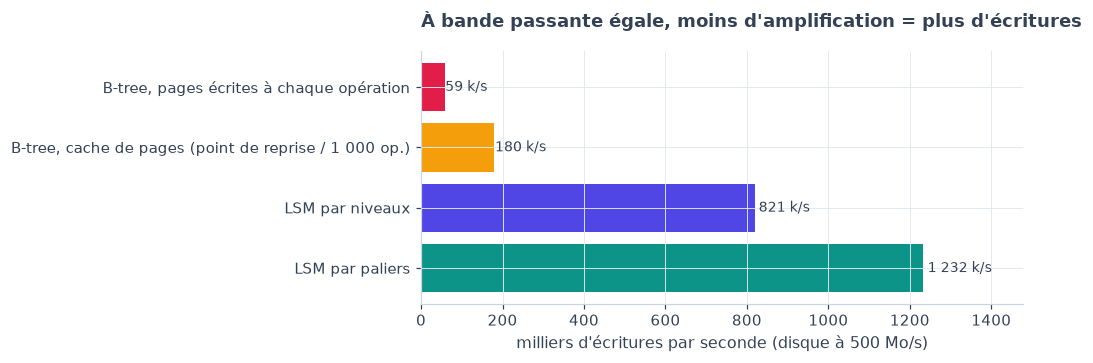

In [13]:
bw = 500e6
debit = (bw / (rec_bytes * comp["amplification d'écriture"])).rename("écritures par seconde soutenables")
fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.barh(range(len(debit)), debit / 1e3, color=[ROSE, AMBER, INDIGO, TEAL])
ax.set_yticks(range(len(debit)), debit.index)
ax.invert_yaxis()
for y, v in enumerate(debit / 1e3):
    ax.text(v * 1.01, y, f"{v:,.0f} k/s".replace(",", " "), va="center", fontsize=9)
ax.set_xlabel("milliers d'écritures par seconde (disque à 500 Mo/s)")
ax.set_title("À bande passante égale, moins d'amplification = plus d'écritures")
ax.set_xlim(right=debit.max() / 1e3 * 1.2)
plt.tight_layout(); plt.show()

Les SSD s'usent à force d'écritures (un nombre limité de cycles d'effacement) :
l'amplification d'écriture se traduit aussi en **durée de vie** du disque. Un moteur
moins amplificateur use moins vite ses SSD.

### Écritures séquentielles ou aléatoires (section *Advantages of LSM-trees*)

Un B-tree dont les clés tombent n'importe où dans l'espace des clés réécrit des pages
**dispersées** sur le disque : des **écritures aléatoires**. Un LSM écrit des fichiers
entiers (memtable ou compaction) : de grosses **écritures séquentielles**. L'écart est
énorme sur disque magnétique (déplacement mécanique de la tête), plus réduit mais réel
sur SSD. Traduisons le volume écrit par nos moteurs en temps disque avec le modèle
`S.io_time` : pages aléatoires pour le B-tree, octets séquentiels pour le LSM.

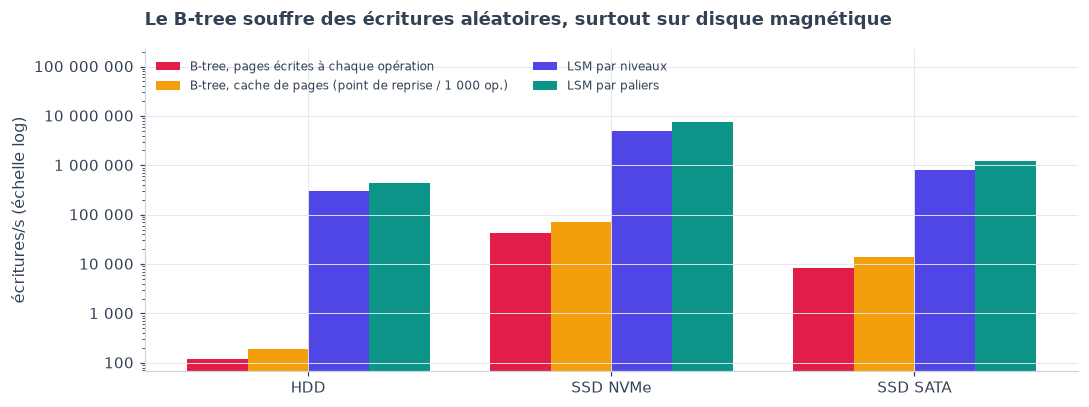

In [14]:
rows = []
for dev in S.DEVICES:
    for nom, m in moteurs.items():
        if isinstance(m, S.BPlusTree):
            temps = S.io_time(dev, n_random=m.page_writes, seq_bytes=m.wal_bytes)
        else:
            temps = S.io_time(dev, seq_bytes=m.bytes_written())
        rows.append(dict(support=dev, moteur=nom, secondes=temps, ecritures_par_s=N_OPS / temps))
io = pd.DataFrame(rows).pivot(index="moteur", columns="support", values="ecritures_par_s").loc[list(moteurs)]
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(io.columns))
for j, (nom, c) in enumerate(zip(io.index, [ROSE, AMBER, INDIGO, TEAL])):
    ax.bar(x + (j - 1.5) * 0.2, io.loc[nom], 0.2, color=c, label=nom)
ax.set_yscale("log"); S.plain_log_ticks(ax)
ax.set_xticks(x, io.columns)
ax.set_ylabel("écritures/s (échelle log)")
ax.set_title("Le B-tree souffre des écritures aléatoires, surtout sur disque magnétique")
ax.legend(fontsize=8, ncol=2, loc="upper left")
ax.set_ylim(top=io.values.max() * 30)
plt.tight_layout(); plt.show()

### Pics de latence et contre-pression (section *Downsides of LSM-trees*)

Le revers des LSM : la compaction partage la bande passante du disque avec les
écritures. Si les écritures arrivent plus vite que la compaction ne peut suivre, les
SSTables de L0 s'accumulent ; beaucoup de moteurs (RocksDB par exemple) appliquent alors
une **contre-pression** : ils suspendent les écritures le temps de rattraper le
retard. Simulons-le : un disque de 100 Mo/s, une amplification d'écriture de 8 (chaque
Mo écrit par le client coûte 7 Mo de compaction), et un débit client qui double pendant
une rafale.

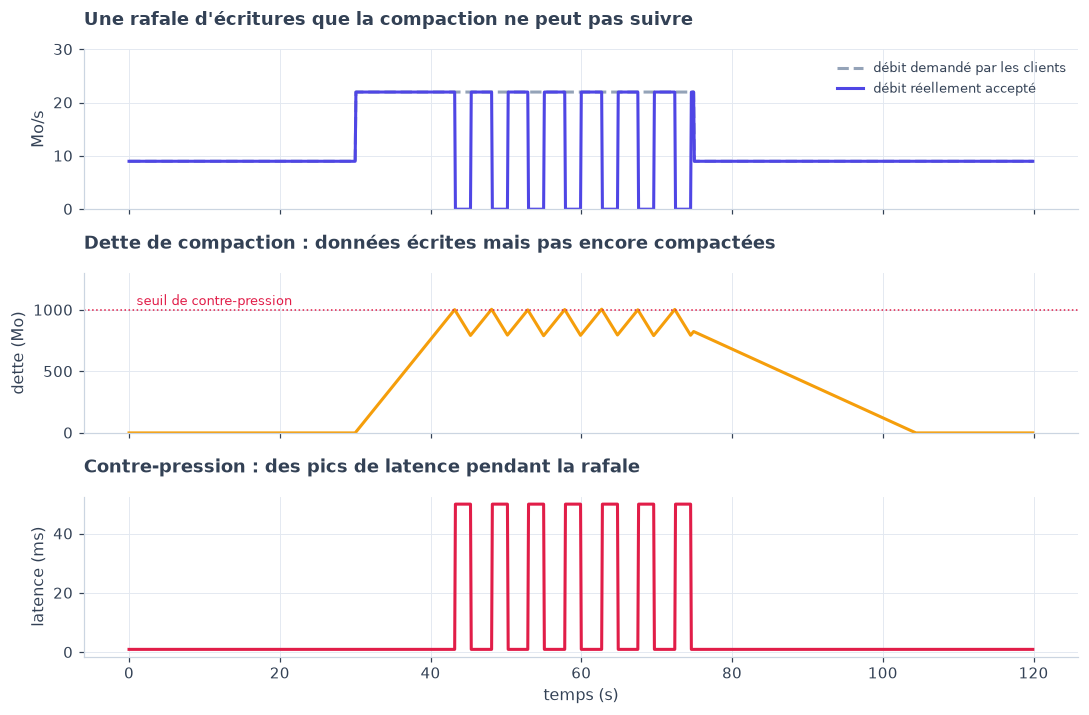

In [15]:
dt, T = 0.1, 120.0
temps = np.arange(0, T, dt)
debit_client = np.where((temps > 30) & (temps < 75), 22.0, 9.0)  # Mo/s demandés
disque, wa = 100.0, 8.0                    # Mo/s de bande passante, amplification d'écriture
seuil_haut, seuil_bas = 1000.0, 800.0      # dette (Mo) qui déclenche / lève la contre-pression
dette, bloque = 0.0, False
servi, dettes, latence = [], [], []
for d_ in debit_client:
    if dette > seuil_haut:
        bloque = True
    elif dette < seuil_bas:
        bloque = False
    ecrit = 0.0 if bloque else d_
    capacite_compaction = disque - ecrit       # bande passante restante pour la compaction
    dette = max(0.0, dette + (ecrit * (wa - 1) - capacite_compaction) * dt)
    servi.append(ecrit)
    dettes.append(dette)
    latence.append(50.0 if bloque else 1.0)   # ms (modèle grossier : attente si suspendu)
fig, axes = plt.subplots(3, 1, figsize=(10, 6.6), sharex=True)
axes[0].plot(temps, debit_client, color=GRAY, ls="--", label="débit demandé par les clients")
axes[0].plot(temps, servi, color=INDIGO, label="débit réellement accepté")
axes[0].set_ylabel("Mo/s"); axes[0].legend(fontsize=8.5, loc="upper right")
axes[0].set_title("Une rafale d'écritures que la compaction ne peut pas suivre")
axes[0].set_ylim(0, 30)
axes[1].plot(temps, dettes, color=AMBER)
axes[1].axhline(seuil_haut, color=ROSE, ls=":", lw=1)
axes[1].text(1, seuil_haut + 40, "seuil de contre-pression", color=ROSE, fontsize=8.5)
axes[1].set_ylabel("dette (Mo)"); axes[1].set_ylim(0, 1300)
axes[1].set_title("Dette de compaction : données écrites mais pas encore compactées")
axes[2].plot(temps, latence, color=ROSE)
axes[2].set_ylabel("latence (ms)"); axes[2].set_xlabel("temps (s)")
axes[2].set_title("Contre-pression : des pics de latence pendant la rafale")
finish(fig)
plt.show()

Tant que le débit client reste sous $\text{disque}/\mathrm{WA} = 12{,}5$ Mo/s, la
compaction suit. Pendant la rafale à 22 Mo/s, il faudrait $22 \times 8 = 176$ Mo/s de
bande passante : la dette grossit d'environ 76 Mo/s, atteint le seuil en une
quinzaine de secondes, puis le moteur alterne suspensions (la compaction rattrape) et
reprises : la latence fait des pics, et le débit moyen accepté retombe vers 12,5 Mo/s. D'où le
conseil du livre : **mesurer assez longtemps**. Un LSM vide paraît très rapide, puisque
rien n'est encore à compacter ; le débit durable n'apparaît qu'une fois la compaction en
régime permanent.

Autres considérations sur les lectures : les **requêtes par intervalle** sont simples et
rapides dans un B-tree (on suit les feuilles) ; dans un LSM, il faut parcourir en
parallèle toutes les SSTables qui chevauchent l'intervalle et fusionner, et les filtres
de Bloom n'aident pas (il faudrait tester toutes les clés possibles de l'intervalle).
Enfin, un B-tree stocke chaque clé à **un seul endroit**, ce qui facilite les verrous
sur des intervalles de clés pour l'isolation transactionnelle (chapitre
7).

### Espace disque (section *Advantages of LSM-trees*)

Un B-tree se **fragmente** : après de nombreuses suppressions, le fichier contient des
pages peu remplies ou libres, réutilisables par l'arbre mais difficiles à rendre au
système (elles sont au milieu du fichier). Il faut un processus de fond qui réorganise
les pages, comme le `VACUUM` de PostgreSQL. Un LSM réécrit régulièrement ses fichiers et
ses SSTables n'ont pas de pages à moitié vides ; ses blocs se compressent mieux. Les
valeurs écrasées occupent de l'espace jusqu'à leur compaction, mais peu en leveled.
Mesurons : on insère 60 000 clés, puis on en supprime 70 % au hasard.

In [16]:
rng = random.Random(9)
tous = [S.kv_key(i) for i in range(60_000)]
supprimes = set(rng.sample(tous, 42_000))
bt = S.BPlusTree(max_keys=32, page_bytes=4096, record_bytes=rec_bytes)
lsm = S.LSMTree(memtable_bytes=256 * 1024, strategy="leveled")
for k in rng.sample(tous, len(tous)):
    bt.insert(k, 1)
    lsm.put(k, S.kv_value(0))
pages_avant, lsm_avant = len(bt.pages), lsm.disk_bytes()
for k in supprimes:
    bt.delete(k)
    lsm.delete(k)
for i in range(60_000, 90_000):  # la vie continue : de nouvelles clés arrivent (en fin d'intervalle)
    lsm.put(S.kv_key(i), S.kv_value(i))
    bt.insert(S.kv_key(i), 1)
vivantes = 60_000 - 42_000 + 30_000
esp = pd.DataFrame({
    "B-tree": [len(bt.pages) * 4096 / 1e6, vivantes * rec_bytes / 1e6, bt.fill_factor()],
    "LSM par niveaux": [lsm.disk_bytes() / 1e6, lsm.live_bytes() / 1e6, lsm.live_bytes() / lsm.disk_bytes()],
}, index=["Mo occupés", "Mo de données vivantes", "taux d'utilisation"]).T
esp

,Mo occupés,Mo de données vivantes,taux d'utilisation
B-tree,19.673,5.952,0.329
LSM par niveaux,8.520,5.952,0.699


Après les suppressions, le B-tree garde toutes ses pages (on ne fusionne pas les pages
presque vides) : son taux d'utilisation s'effondre, alors que les nouvelles clés, qui
arrivent en fin d'intervalle, ne peuvent pas réutiliser les trous laissés au milieu. Le
LSM, lui, a éliminé les valeurs supprimées en compactant (les tombstones disparaissent
au dernier niveau) : son taux d'utilisation reste élevé.

Deux autres points du livre :

- l'immuabilité des SSTables rend les **instantanés** faciles (pour une sauvegarde) : il
  suffit d'écrire la memtable et de noter la liste des fichiers, sans rien copier ;
- à l'inverse, une donnée supprimée peut survivre longtemps dans les niveaux bas d'un
  LSM, tant que son tombstone n'a pas traversé tous les niveaux.

> **À retenir.** B-tree : lectures rapides et prévisibles, intervalles faciles, chaque
> clé à un seul endroit ; mais écritures aléatoires, pages entières réécrites et
> fragmentation. LSM : écritures séquentielles, amplification d'écriture plus faible,
> fichiers compacts ; mais lectures qui dépendent de la compaction et pics de latence si
> elle ne suit pas. Il faut mesurer avec sa propre charge, assez longtemps.

## Synthèse

- Un **B-tree** découpe la base en pages fixes réécrites en place ; l'éclatement garde
  l'arbre équilibré, de hauteur $\log_b n$ (trois ou quatre niveaux en pratique).
- Un éclatement modifie plusieurs pages : sans **WAL**, une panne peut corrompre l'arbre
  et perdre des clés anciennes. Le WAL (journal, `fsync`, puis pages) répare et permet de
  différer les écritures de pages.
- Les variantes jouent sur la fiabilité (copie sur écriture), le branchement (clés
  abrégées) et les parcours (feuilles chaînées).
- **B-tree contre LSM** : lectures prévisibles contre écritures séquentielles ;
  amplification d'écriture, fragmentation, pics de latence de compaction. Aucun ne gagne
  partout.

**Liens.** Le WAL et la copie sur écriture reviennent avec les transactions et
l'isolation par instantanés (chapitre 7) ; le journal de réplication
s'appuie souvent sur le WAL (chapitre 5). Le cours 4 passe aux index
secondaires, multidimensionnels et plein texte.